# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання
**Прізвище, ім’я:** Юксін Антон
**Група:** ФІТ-48
**Дата:** 19.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Фіксуємо seed для відтворюваності (ініціалізація ваг, Dropout, перемішування)
SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1
NumPy: 2.5.5


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("x_train:", x_train_full.shape, x_train_full.dtype)
print("y_train:", y_train_full.shape, y_train_full.dtype)
print("x_test: ", x_test.shape, x_test.dtype)
print("y_test: ", y_test.shape, y_test.dtype)
print("Кількість класів:", len(class_names))

# Розподіл класів у навчальній вибірці
counts = np.bincount(y_train_full, minlength=10)
for i, (name, cnt) in enumerate(zip(class_names, counts)):
    print(f"  {i}: {name:12s} — {cnt}")

x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test:  (10000, 28, 28) uint8
y_test:  (10000,) uint8
Кількість класів: 10
  0: T-shirt/top  — 6000
  1: Trouser      — 6000
  2: Pullover     — 6000
  3: Dress        — 6000
  4: Coat         — 6000
  5: Sandal       — 6000
  6: Shirt        — 6000
  7: Sneaker      — 6000
  8: Bag          — 6000
  9: Ankle boot   — 6000


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

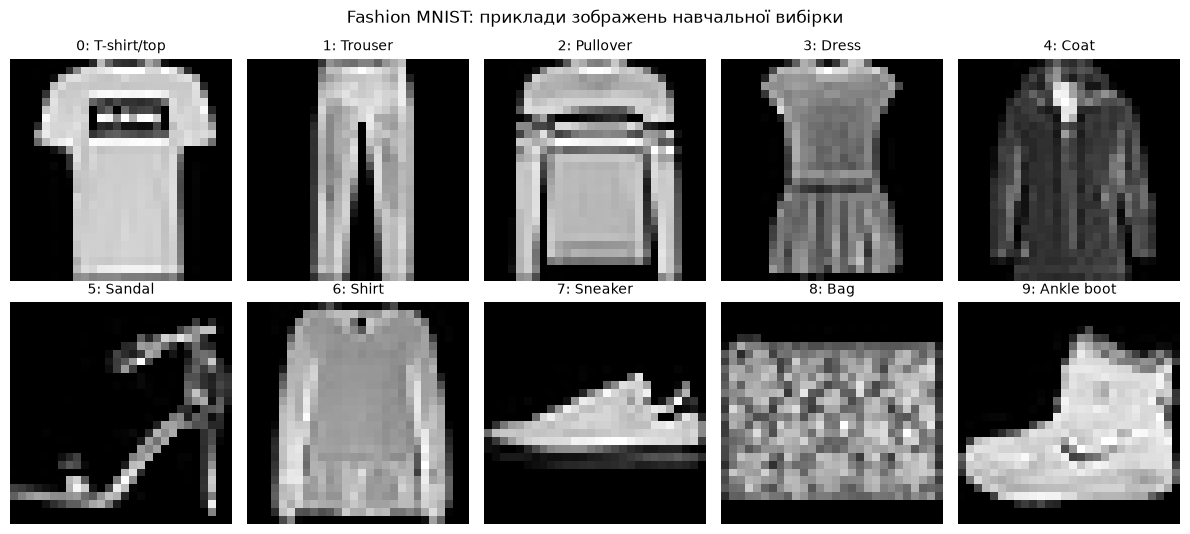

In [3]:
# По одному зображенню кожного з 10 класів (перше входження в навчальній вибірці)
first_idx = [int(np.flatnonzero(y_train_full == c)[0]) for c in range(10)]

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, idx in zip(axes.flat, first_idx):
    ax.imshow(x_train_full[idx], cmap='gray')
    ax.set_title(f"{y_train_full[idx]}: {class_names[y_train_full[idx]]}", fontsize=10)
    ax.axis('off')
plt.suptitle('Fashion MNIST: приклади зображень навчальної вибірки')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
print("До нормалізації:", x_train_full.dtype, x_train_full.min(), "…", x_train_full.max())

x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Після нормалізації:", x_train_full.dtype,
      f"train [{x_train_full.min():.1f}; {x_train_full.max():.1f}],",
      f"test [{x_test.min():.1f}; {x_test.max():.1f}]")
assert x_train_full.min() >= 0 and x_train_full.max() <= 1

До нормалізації: uint8 0 … 255


Після нормалізації: float32 train [0.0; 1.0], test [0.0; 1.0]


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
def create_model(learning_rate=1e-3):
    model = keras.Sequential([
        keras.Input(shape=(28, 28), name='image'),
        layers.Flatten(name='flatten'),                       # 28×28 → вектор із 784 ознак
        layers.Dense(256, activation='relu', name='dense_256'),
        layers.Dropout(0.3, name='dropout_1'),
        layers.Dense(128, activation='relu', name='dense_128'),
        layers.Dropout(0.3, name='dropout_2'),
        layers.Dense(10, activation='softmax', name='classes'),  # 10 класів
    ], name='fashion_mlp')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),   # мітки — цілі числа 0..9
        metrics=['accuracy'],
    )
    return model


keras.utils.set_random_seed(SEED)
model = create_model(learning_rate=1e-3)
print("Модель створено та скомпільовано.")
print("Оптимізатор:", type(model.optimizer).__name__,
      "| learning_rate =", float(model.optimizer.learning_rate.numpy()))

Модель створено та скомпільовано.
Оптимізатор: Adam | learning_rate = 0.0010000000474974513


**Обґрунтування вибору параметрів моделі.**

- **Кількість нейронів (256 → 128).** На вхід надходять 784 пікселі, тому перший шар має бути достатньо широким, щоб виділити різноманітні ознаки силуету одягу. 256 нейронів — компроміс між здатністю моделі та кількістю параметрів (≈ 200 тис. у першому шарі). Другий шар удвічі вужчий (128): він поступово стискає ознаки до 10 класів. Двох прихованих шарів достатньо для порогу 0,87, а глибша повнозв'язна мережа на Fashion MNIST помітного виграшу не дає і швидше перенавчається.
- **Dropout 0,3.** Модель має понад 235 тис. параметрів при 54 тис. навчальних прикладів, тому регуляризація потрібна. Значення 0,3 достатньо сильне, щоб стримати перенавчання, але не настільки, щоб модель недонавчалась (при 0,5 вона б повільніше збігалась).
- **Швидкість навчання 0,001** — рекомендоване значення для Adam, яке зазвичай забезпечує стабільне навчання. Більше значення (0,01) дає різкі коливання втрат, а менше (0,0001) суттєво сповільнює навчання. Крім того, `ReduceLROnPlateau` на наступному кроці автоматично зменшуватиме швидкість навчання, коли валідаційні втрати перестануть покращуватися.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Валідаційна частина — 10% навчальної вибірки (стратифіковано); тест не використовується
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.1, random_state=SEED, stratify=y_train_full
)
print("Навчальна:  ", x_train.shape, "| Валідаційна:", x_val.shape, "| Тестова:", x_test.shape)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=callbacks,
    verbose=2,
)

epochs_trained = len(history.history['loss'])
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f"\nНавчання тривало {epochs_trained} епох; найкраща епоха за val_loss — {best_epoch} "
      f"(val_loss = {min(history.history['val_loss']):.4f}, "
      f"val_accuracy = {history.history['val_accuracy'][best_epoch - 1]:.4f})")

Навчальна:   (54000, 28, 28) | Валідаційна: (6000, 28, 28) | Тестова: (10000, 28, 28)


Epoch 1/50


422/422 - 3s - 7ms/step - accuracy: 0.7745 - loss: 0.6356 - val_accuracy: 0.8495 - val_loss: 0.4081 - learning_rate: 0.0010


Epoch 2/50


422/422 - 2s - 5ms/step - accuracy: 0.8396 - loss: 0.4435 - val_accuracy: 0.8638 - val_loss: 0.3687 - learning_rate: 0.0010


Epoch 3/50


... (73 outputs left out)

422/422 - 2s - 5ms/step - accuracy: 0.9261 - loss: 0.1926 - val_accuracy: 0.9068 - val_loss: 0.2623 - learning_rate: 1.0000e-05


Epoch 36: early stopping


Restoring model weights from the end of the best epoch: 31.



Навчання тривало 36 епох; найкраща епоха за val_loss — 31 (val_loss = 0.2621, val_accuracy = 0.9063)


### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()

hidden_dense = [l for l in model.layers if isinstance(l, layers.Dense) and l.name != 'classes']
print("Кількість шарів:", len(model.layers))
print("Прихованих Dense-шарів:", len(hidden_dense), "| нейронів:", [l.units for l in hidden_dense])
print("Загальна кількість параметрів:", model.count_params())
for l in model.layers:
    print(f"  {l.name:10s} {type(l).__name__:8s} параметрів: {l.count_params()}")

Model: "fashion_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Прихованих Dense-шарів: 2 | нейронів: [256, 128]
Загальна кількість параметрів: 235146
  flatten    Flatten  параметрів: 0
  dense_256  Dense    параметрів: 200960
  dropout_1  Dropout  параметрів: 0
  dense_128  Dense    параметрів: 32896
  dropout_2  Dropout  параметрів: 0
  classes    Dense    параметрів: 1290


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# У Google Colab за потреби можна зберегти модель на Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')
# model_path = '/content/drive/MyDrive/fashion_mlp_task1.keras'

model_path = 'fashion_mlp_task1.keras'
model.save(model_path)

# Перевірка: завантажена модель дає ті самі прогнози
restored = keras.models.load_model(model_path)
np.testing.assert_allclose(model.predict(x_val[:100], verbose=0),
                           restored.predict(x_val[:100], verbose=0), atol=1e-6)
import os
print(f"Модель збережено: {model_path} ({os.path.getsize(model_path) / 1024:.0f} КБ), відновлення перевірено.")

Модель збережено: fashion_mlp_task1.keras (2787 КБ), відновлення перевірено.


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

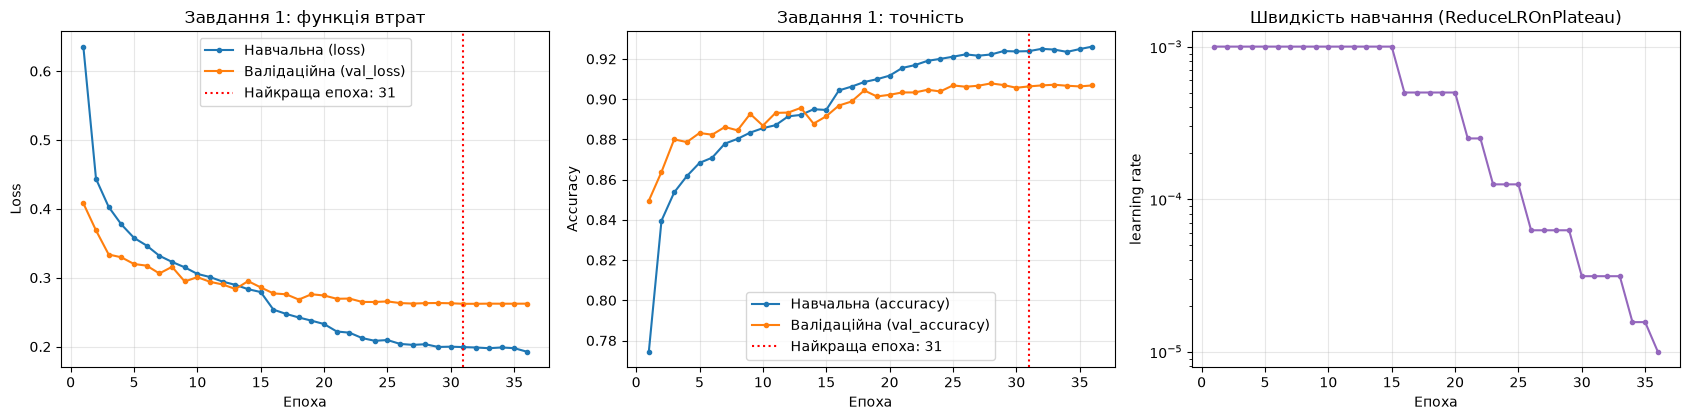

In [9]:
def plot_history(hist, title):
    h = hist.history
    ep = np.arange(1, len(h['loss']) + 1)
    best = int(np.argmin(h['val_loss'])) + 1
    has_lr = 'learning_rate' in h
    fig, axes = plt.subplots(1, 3 if has_lr else 2, figsize=(17 if has_lr else 12, 4.3))

    axes[0].plot(ep, h['loss'], marker='o', ms=3, label='Навчальна (loss)')
    axes[0].plot(ep, h['val_loss'], marker='o', ms=3, label='Валідаційна (val_loss)')
    axes[0].axvline(best, color='red', linestyle=':', label=f'Найкраща епоха: {best}')
    axes[0].set(title=f'{title}: функція втрат', xlabel='Епоха', ylabel='Loss')

    axes[1].plot(ep, h['accuracy'], marker='o', ms=3, label='Навчальна (accuracy)')
    axes[1].plot(ep, h['val_accuracy'], marker='o', ms=3, label='Валідаційна (val_accuracy)')
    axes[1].axvline(best, color='red', linestyle=':', label=f'Найкраща епоха: {best}')
    axes[1].set(title=f'{title}: точність', xlabel='Епоха', ylabel='Accuracy')

    if has_lr:
        axes[2].plot(ep, h['learning_rate'], marker='o', ms=3, color='tab:purple')
        axes[2].set(title='Швидкість навчання (ReduceLROnPlateau)', xlabel='Епоха',
                    ylabel='learning rate', yscale='log')
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[0].legend(); axes[1].legend()
    plt.tight_layout()
    plt.show()


plot_history(history, 'Завдання 1')

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(f"Тестові втрати (loss): {test_loss:.4f}")
print(f"Тестова точність (accuracy): {test_accuracy:.4f}")
print("Вимогу accuracy ≥ 0,87", "ВИКОНАНО" if test_accuracy >= 0.87 else "НЕ виконано",
      f"(запас {test_accuracy - 0.87:+.4f})")
print()
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Тестові втрати (loss): 0.3081
Тестова точність (accuracy): 0.8950
Вимогу accuracy ≥ 0,87 ВИКОНАНО (запас +0.0250)

              precision    recall  f1-score   support

 T-shirt/top      0.843     0.852     0.847      1000
     Trouser      0.992     0.971     0.981      1000
    Pullover      0.824     0.817     0.821      1000
       Dress      0.882     0.904     0.893      1000
        Coat      0.811     0.824     0.817      1000
      Sandal      0.975     0.972     0.973      1000
       Shirt      0.726     0.708     0.717      1000
     Sneaker      0.946     0.968     0.957      1000
         Bag      0.978     0.978     0.978      1000
  Ankle boot      0.973     0.956     0.964      1000

    accuracy                          0.895     10000
   macro avg      0.895     0.895     0.895     10000
weighted avg      0.895     0.895     0.895     10000



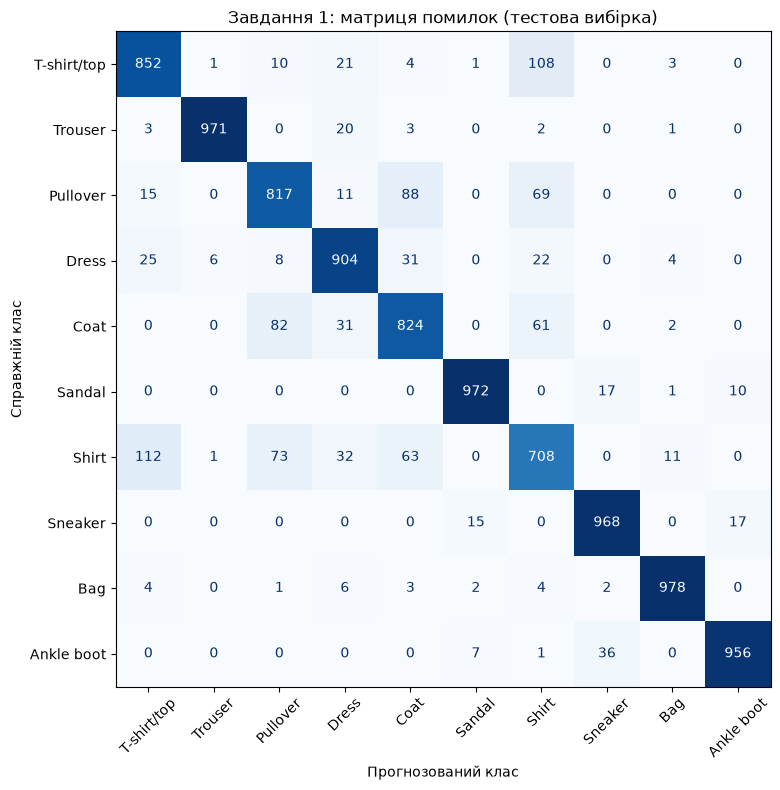

Найчастіші помилки (справжній → прогноз):
  Shirt        → T-shirt/top : 112
  T-shirt/top  → Shirt       : 108
  Pullover     → Coat        : 88
  Coat         → Pullover    : 82
  Shirt        → Pullover    : 73
  Pullover     → Shirt       : 69

Помилок за класами: {'T-shirt/top': 148, 'Trouser': 29, 'Pullover': 183, 'Dress': 96, 'Coat': 176, 'Sandal': 28, 'Shirt': 292, 'Sneaker': 32, 'Bag': 22, 'Ankle boot': 44}


In [11]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False,
                                                             values_format='d', xticks_rotation=45)
ax.set_title('Завдання 1: матриця помилок (тестова вибірка)')
ax.set_xlabel('Прогнозований клас')
ax.set_ylabel('Справжній клас')
plt.tight_layout()
plt.show()

# Найчастіші пари помилок
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0), reverse=True)[:6]
print("Найчастіші помилки (справжній → прогноз):")
for n, i, j in pairs:
    print(f"  {class_names[i]:12s} → {class_names[j]:12s}: {n}")
errors_per_class = cm.sum(axis=1) - np.diag(cm)
print("\nПомилок за класами:", dict(zip(class_names, errors_per_class.tolist())))

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

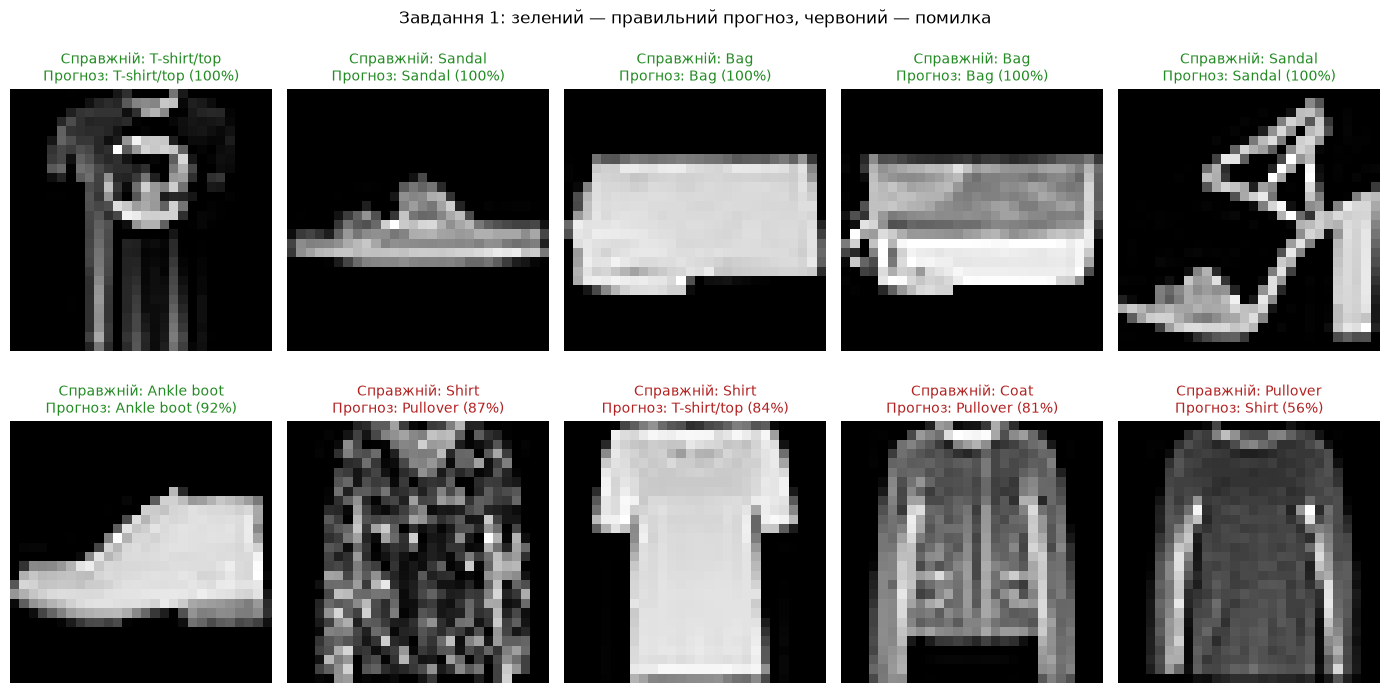

Правильних серед показаних: 6 з 10


In [12]:
def show_predictions(x, y_true, y_hat, probs, indices, title):
    fig, axes = plt.subplots(2, 5, figsize=(14, 7.5))
    for ax, idx in zip(axes.flat, indices):
        ok = y_hat[idx] == y_true[idx]
        ax.imshow(x[idx], cmap='gray')
        ax.set_title(f"Справжній: {class_names[y_true[idx]]}\n"
                     f"Прогноз: {class_names[y_hat[idx]]} ({probs[idx].max():.0%})",
                     color='forestgreen' if ok else 'firebrick', fontsize=10)
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# 7 випадкових тестових зображень + 3 приклади помилок (усього 10)
rng = np.random.default_rng(SEED)
wrong = np.flatnonzero(y_pred != y_test)
shown = list(rng.choice(len(x_test), size=7, replace=False)) + list(rng.choice(wrong, size=3, replace=False))
show_predictions(x_test, y_test, y_pred, probabilities, shown,
                 'Завдання 1: зелений — правильний прогноз, червоний — помилка')
print("Правильних серед показаних:", int(sum(y_pred[i] == y_test[i] for i in shown)), "з 10")

**Проміжний висновок до завдання 1**

**Ваш висновок:**  
Модель із двома прихованими шарами (256 і 128 нейронів, Dropout 0,3, Adam з початковою швидкістю 0,001) навчалась 36 епох. EarlyStopping зупинив навчання і відновив ваги з 31-ї епохи, де `val_loss` = 0,2621 і `val_accuracy` = 0,906. ReduceLROnPlateau п'ять разів зменшував швидкість навчання — з 0,001 до 1·10⁻⁵. Саме після першого зменшення (15-та епоха) валідаційні втрати помітно знизились. На тестовій вибірці отримано **accuracy = 0,8950** і loss = 0,3081, отже **вимогу точності не нижче 0,87 виконано** із запасом 0,025. Найбільше помилок у класі **Shirt** (292 із 1000, F1 = 0,717): сорочки плутаються з футболками (112), светрами (73) і пальтами (63). Також складні **Pullover** (183 помилки) і **Coat** (176), які плутаються між собою (88 і 82 випадки), та **T-shirt/top** (148). Це предмети одягу верхньої частини тіла зі схожим силуетом, тоді як взуття, сумки й штани модель розпізнає майже безпомилково (F1 = 0,96–0,98). Наприкінці навчання з'явився невеликий розрив між навчальною (0,924) і валідаційною (0,906) точністю — це помірна ознака перенавчання, яку стримують Dropout та рання зупинка.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [13]:
%pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras import regularizers

print("Keras Tuner:", kt.__version__)

Note: you may need to restart the kernel to use updated packages.


Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:
# Використовуємо ті самі нормалізовані дані та ТЕ САМЕ розбиття train/val, що й у завданні 1.
# Тестова вибірка (x_test, y_test) у пошуку не бере участі.
print("Для пошуку:  x_train", x_train.shape, "| x_val", x_val.shape)
print("Для фіналу:  x_test ", x_test.shape)
print("Діапазон пікселів:", x_train.min(), "…", x_train.max())
assert len(x_train) + len(x_val) == 60000 and len(x_test) == 10000

Для пошуку:  x_train (54000, 28, 28) | x_val (6000, 28, 28)
Для фіналу:  x_test  (10000, 28, 28)


Діапазон пікселів: 0.0 … 1.0


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:
L2_FACTOR = 1e-4      # L2-регуляризація ваг (фіксована)
DROPOUT_RATE = 0.2    # Dropout після кожного прихованого шару (фіксований)


def build_model(hp):
    model = keras.Sequential(name='fashion_tuned')
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    # Кількість прихованих шарів: 1–3
    for i in range(hp.Int('num_layers', min_value=1, max_value=3)):
        # Кількість нейронів у кожному шарі: 32–512 з кроком 32
        model.add(Dense(
            units=hp.Int(f'units_{i}', min_value=32, max_value=512, step=32),
            activation='relu',
            kernel_regularizer=regularizers.l2(L2_FACTOR),
        ))
        model.add(Dropout(DROPOUT_RATE))

    model.add(Dense(10, activation='softmax'))

    # Швидкість навчання: 0.01, 0.001, 0.0001
    learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy'],
    )
    return model


# Перевірка: функція повертає скомпільовану модель для значень за замовчуванням
build_model(kt.HyperParameters()).summary()

Model: "fashion_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,              # 3 спроби, як у вихідній роботі
    executions_per_trial=1,    # 1 навчання на спробу
    seed=SEED,
    directory='keras_tuner_results',
    project_name='fashion_mnist_lr10',
    overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:
search_callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
]

tuner.search(
    x_train, y_train,
    validation_data=(x_val, y_val),   # лише навчальні та валідаційні дані
    epochs=30,
    batch_size=128,
    callbacks=search_callbacks,
    verbose=2,
)

Trial 3 Complete [00h 01m 05s]
val_accuracy: 0.8939999938011169

Best val_accuracy So Far: 0.9106666445732117
Total elapsed time: 00h 03m 02s


In [18]:
# Результати всіх спроб
tuner.results_summary(num_trials=3)

trials = tuner.oracle.get_best_trials(num_trials=3)
print("\nПідсумок спроб (від найкращої):")
for rank, t in enumerate(trials, 1):
    hp_vals = t.hyperparameters.values
    n = hp_vals['num_layers']
    units = [hp_vals[f'units_{i}'] for i in range(n)]
    print(f"  {rank}. шарів = {n}, нейрони = {units}, lr = {hp_vals['learning_rate']}, "
          f"val_accuracy = {t.score:.4f}")

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_layers = best_hp.get('num_layers')
best_units = [best_hp.get(f'units_{i}') for i in range(best_layers)]
best_lr = best_hp.get('learning_rate')
print(f"\nНайкращі гіперпараметри: шарів = {best_layers}, нейрони = {best_units}, learning_rate = {best_lr}")

Results summary
Results in keras_tuner_results/fashion_mnist_lr10
Showing 3 best trials
Objective(name="val_accuracy", direction="max")

Trial 1 summary
Hyperparameters:
num_layers: 1
units_0: 480
learning_rate: 0.001
units_1: 288
Score: 0.9106666445732117

Trial 2 summary
Hyperparameters:
num_layers: 1
units_0: 256
learning_rate: 0.01
units_1: 512
Score: 0.8939999938011169

Trial 0 summary
Hyperparameters:
num_layers: 2
units_0: 32
learning_rate: 0.001
units_1: 32
Score: 0.8871666789054871

Підсумок спроб (від найкращої):
  1. шарів = 1, нейрони = [480], lr = 0.001, val_accuracy = 0.9107
  2. шарів = 1, нейрони = [256], lr = 0.01, val_accuracy = 0.8940
  3. шарів = 2, нейрони = [32, 32], lr = 0.001, val_accuracy = 0.8872

Найкращі гіперпараметри: шарів = 1, нейрони = [480], learning_rate = 0.001


In [19]:
# Перенавчаємо обрану конфігурацію з нуля, щоб зберегти повну історію навчання
keras.utils.set_random_seed(SEED)
best_model = tuner.hypermodel.build(best_hp)
best_model.summary()

best_history = best_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    ],
    verbose=2,
)
tuned_epochs = len(best_history.history['loss'])
tuned_best_epoch = int(np.argmin(best_history.history['val_loss'])) + 1
print(f"\nНавчання тривало {tuned_epochs} епох; найкраща епоха — {tuned_best_epoch} "
      f"(val_accuracy = {best_history.history['val_accuracy'][tuned_best_epoch - 1]:.4f})")
best_model.save('fashion_mlp_tuned.keras')

Model: "fashion_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


... (101 outputs left out)

Epoch 50/50


422/422 - 2s - 6ms/step - accuracy: 0.9454 - loss: 0.2006 - val_accuracy: 0.9118 - val_loss: 0.2917 - learning_rate: 6.2500e-05


Restoring model weights from the end of the best epoch: 50.



Навчання тривало 50 епох; найкраща епоха — 50 (val_accuracy = 0.9118)


### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Модель після Keras Tuner: тестові втрати = 0.3345, тестова точність = 0.8991
Модель із завдання 1:     тестові втрати = 0.3081, тестова точність = 0.8950
Різниця точності: +0.0041

              precision    recall  f1-score   support

 T-shirt/top      0.855     0.851     0.853      1000
     Trouser      0.995     0.976     0.985      1000
    Pullover      0.814     0.827     0.820      1000
       Dress      0.895     0.913     0.904      1000
        Coat      0.829     0.822     0.825      1000
      Sandal      0.982     0.965     0.973      1000
       Shirt      0.730     0.731     0.730      1000
     Sneaker      0.951     0.968     0.959      1000
         Bag      0.982     0.973     0.977      1000
  Ankle boot      0.963     0.965     0.964      1000

    accuracy                          0.899     10000
   macro avg      0.899     0.899     0.899     10000
weighted avg      0.899     0.899     0.899     10000



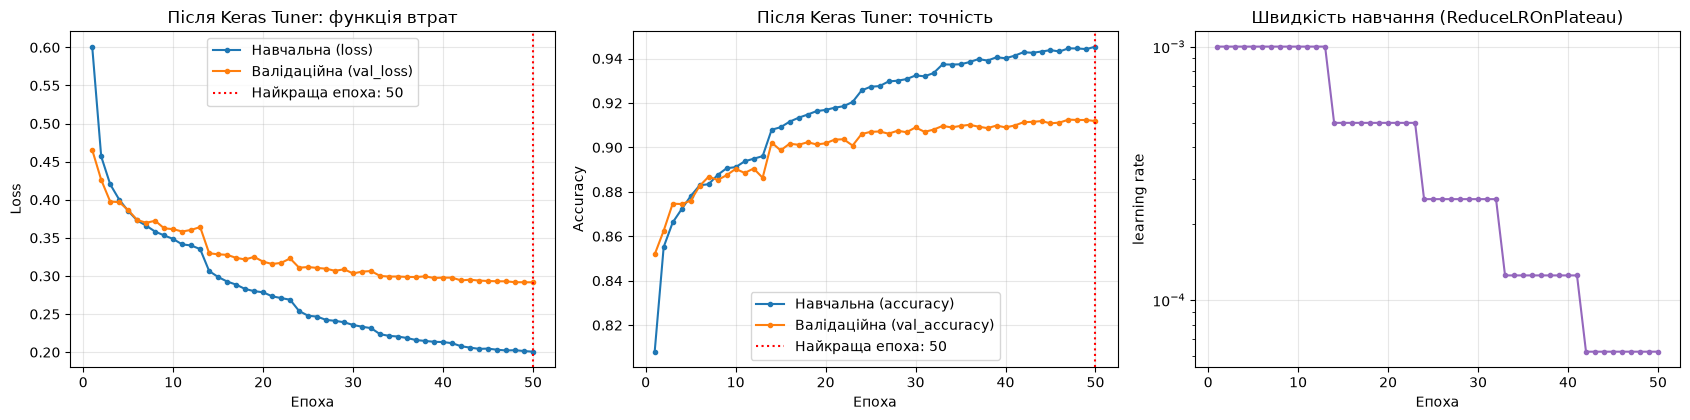

In [20]:
tuned_test_loss, tuned_test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
tuned_probs = best_model.predict(x_test, verbose=0)
tuned_pred = np.argmax(tuned_probs, axis=1)

print(f"Модель після Keras Tuner: тестові втрати = {tuned_test_loss:.4f}, тестова точність = {tuned_test_accuracy:.4f}")
print(f"Модель із завдання 1:     тестові втрати = {test_loss:.4f}, тестова точність = {test_accuracy:.4f}")
print(f"Різниця точності: {tuned_test_accuracy - test_accuracy:+.4f}")
print()
print(classification_report(y_test, tuned_pred, target_names=class_names, digits=3))

plot_history(best_history, 'Після Keras Tuner')

In [21]:
# Зведена таблиця для висновків
import pandas as pd

task1_units = [l.units for l in model.layers if isinstance(l, layers.Dense) and l.name != 'classes']
summary_table = pd.DataFrame({
    'Модель із завдання 1': [len(task1_units), str(task1_units), 1e-3,
                             round(test_accuracy, 4), round(test_loss, 4),
                             f"{epochs_trained} (найкраща {best_epoch})", model.count_params()],
    'Модель після Keras Tuner': [best_layers, str(best_units), best_lr,
                                 round(tuned_test_accuracy, 4), round(tuned_test_loss, 4),
                                 f"{tuned_epochs} (найкраща {tuned_best_epoch})", best_model.count_params()],
}, index=['Кількість прихованих шарів', 'Кількість нейронів', 'Швидкість навчання (початкова)',
          'Точність на тестовій вибірці (accuracy)', 'Втрати на тестовій вибірці (loss)',
          'Кількість епох навчання', 'Кількість параметрів'])
display(summary_table)

# F1-score за класами для обох моделей
from sklearn.metrics import f1_score
f1_table = pd.DataFrame({
    'Завдання 1': f1_score(y_test, y_pred, average=None),
    'Keras Tuner': f1_score(y_test, tuned_pred, average=None),
}, index=class_names).round(3).sort_values('Завдання 1')
display(f1_table)

,Модель із завдання 1,Модель після Keras Tuner
Кількість прихованих шарів,2,1
Кількість нейронів,"[256, 128]",[480]
Швидкість навчання (початкова),0.001,0.001
Точність на тестовій вибірці (accuracy),0.895,0.8991
Втрати на тестовій вибірці (loss),0.3081,0.3345
Кількість епох навчання,36 (найкраща 31),50 (найкраща 50)
Кількість параметрів,235146,381610


,Завдання 1,Keras Tuner
Shirt,0.717,0.730
Coat,0.817,0.825
Pullover,0.821,0.820
T-shirt/top,0.847,0.853
Dress,0.893,0.904
Sneaker,0.957,0.959
Ankle boot,0.964,0.964
Sandal,0.973,0.973
Bag,0.978,0.977
Trouser,0.981,0.985


# Висновки. Порівняння моделей

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128 | 480 |
| Швидкість навчання | 0,001 (Adam, далі зменшувалась ReduceLROnPlateau до 1·10⁻⁵) | 0,001 (Adam, далі зменшувалась ReduceLROnPlateau до 6,25·10⁻⁵) |
| Точність на тестовій вибірці (accuracy) | 0,8950 | 0,8991 |
| Втрати на тестовій вибірці (loss) | 0,3081 | 0,3345* |
| Кількість епох навчання | 36 (найкраща — 31) | 50 (найкраща — 50) |

\* Втрати моделі після Keras Tuner включають штраф L2-регуляризації, тому напряму з втратами моделі із завдання 1 (без L2) їх порівнювати некоректно.

**Власні висновки:**  
1. **Так, точність не нижче 0,87 у завданні 1 досягнуто:** тестова accuracy = 0,8950, тобто на 0,025 вище за поріг.
2. **Оптимізація гіперпараметрів покращила точність лише незначно:** з 0,8950 до 0,8991 (+0,41 п. п., або 41 додатковий правильний прогноз із 10 000). F1-score зріс для більшості класів, найбільше — для Shirt (0,717 → 0,730) і Dress (0,893 → 0,904). Обидві моделі близькі до межі можливостей повнозв'язної мережі на цьому наборі.
3. **Найкращі гіперпараметри:** один прихований шар на **480 нейронів** зі швидкістю навчання **0,001** (val_accuracy під час пошуку 0,9107). Друга спроба (1 шар × 256 нейронів, lr = 0,01) дала 0,8940, бо занадто велика швидкість навчання гірше збігається. Третя (2 шари × 32 нейрони, lr = 0,001) дала 0,8872, бо модель надто мала. Результати можуть відрізнятися між запусками з кількох причин. RandomSearch перевіряє лише 3 випадкові комбінації з тисяч можливих, тож з іншим seed буде обрано інші конфігурації. Початкові ваги, Dropout і порядок мініпакетів теж випадкові. Крім того, різниця між найкращими варіантами (десяті частки відсотка) порівнянна з природним розкидом результатів від запуску до запуску. Для надійного висновку варто збільшити `max_trials` і `executions_per_trial`.
4. **Найскладніше класифікувати** класи **Shirt** (F1 ≈ 0,72–0,73), **Pullover** і **Coat** (≈ 0,82), а також **T-shirt/top** (≈ 0,85). Це схожі за формою предмети верхнього одягу, які на зображеннях 28×28 у відтінках сірого відрізняються лише дрібними деталями (комір, ґудзики, довжина рукава). Повнозв'язна мережа не враховує просторову структуру зображення, тому для подальшого покращення доцільно використати згорткові мережі (CNN).

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.